# Alpha Diversity - Rarefaction and Extrapolation Curves

To determine whether sampling was sufficient to capture true diversity, we generated rarefaction curves based on the cumulative accumulation of saproxylic fungi identified across three variables: transect, wood texture, and wood type.

> **Rarefaction** is a statistical technique used to down-sample larger datasets to a common number of individuals or observations. This allows you to compare the species richness of a large sample (e.g., a deep soil core) with a small sample (e.g., a surface litter sample) on an equal footing by "reducing" the larger sample to match the size of the smaller one.

> **Extrapolation** is a predictive technique used to up-sample or estimate how many additional species you would find if you continued sampling at the same rate. It attempts to project the species accumulation curve toward its asymptotic limit (the point where no new species are being added).

**The Curve Shape**
* ***Ascending Curve***: If the curve is still trending upwards, it suggests that as you continue to sample more individuals, you are likely to encounter even more new species. Your sampling effort may not be sufficient to capture the full diversity of the community.
* ***Plateauing (Flattening) Curve***: If the curve levels off (reaches an asymptote), it indicates that increasing the sampling effort is no longer yielding many new species. This suggests your sampling is comprehensive for that specific environment.

**Shading Width**
* ***Narrowest at Reference Point***: The shading pinches tightly around your actual observed sample because there is zero uncertainty about the data you already collected.
* ***Wider during Extrapolation***: The shading gets wider as you move right into the dashed line because predicting unknown data introduces more variance.

**Line Style Meanings**
* **Solid Line**: The rarefaction (***interpolation***) part. It shows the diversity calculated from the actual, observed data.
* **Dotted/Dashed Line**: The ***extrapolation*** part. It shows the predicted diversity if we were to keep sampling beyond our actual sample size.
* **Solid Circle (Dot)**: ***The reference point***. This marks the actual, unmanipulated sample size and observed diversity.
* **Shaded Ribbon**: The 95% confidence interval for both the observed and predicted diversity.

In [2]:
# Load shared R functions for the Oulanka datasets.
source("../src/oulanka.R")

In [3]:
# For 
suppressMessages(if (!require("iNEXT")) install.packages("iNEXT"))
library(iNEXT)
library(scales)


Attaching package: ‘scales’


The following object is masked from ‘package:viridis’:

    viridis_pal


The following object is masked from ‘package:readr’:

    col_factor




The study is focused on saproxylic fungi communities. So, we grab the relevant data for this analysis, both the community (OTU) data and the environment data.

In [4]:
# Load genus-level saproxylic community data
saproxylic_community_df <- get_saproxylic_community_data(genus=TRUE)
# Load environment data
environment_df <- get_environment_data()

## 1. Diversity by Transect

In [5]:
saproxylic_df <- cbind(environment_df$Transect, saproxylic_community_df)
names(saproxylic_df)[1] =  c("Site")  # Site column
saproxylic_df <- saproxylic_df %>%
    group_by(Site) %>%
    summarise(
        across(2:last_col(), sum),    # OTU counts
        .groups = "drop"
      )

site_names = saproxylic_df$Site

saproxylic_df <- saproxylic_df %>%
    select(-Site)
saproxylic_df <- as.data.frame(t(saproxylic_df))
names(saproxylic_df) <- site_names
head(saproxylic_df)

,A,B,C
,<dbl>,<dbl>,<dbl>
Arachnopeziza,7,0,195
Ascocoryne,0,70,37
Atheliachaete,0,3,0
Botryobasidium,0,6,0
Ceraceomyces,81,4,948
Cistella,14,0,40


In [6]:
# Prepare the abundance list for iNEXT
abundance_list <- lapply(saproxylic_df, function(x) x[x != 0])
abundance_list

$A
 [1]    7   81   14   33    4    3  600   10    3  542    6   32   29  186    7
[16]   81   87  854    3    8   11   23 1944

$B
 [1]   70    3    6    4   10  120    5  137  253   25   33   24    7  157 2251
[16]   56  442    3    3 3919

$C
 [1]  195   37  948   40    5   93   48  196   60    8  933    3    7    3   50
[16]   22    9   81    5   45   21    5  153 1061    5    3   13   11   60    3

In [7]:
# computes rarefaction (interpolation) and extrapolation (prediction) sampling curves for biodiversity 
# standard comparisons across communities using Hill numbers 
# (q=0 for species richness, q=1 for Shannon diversity, and q=2 for Simpson diversity) based on sample size or sample coverage.
inext <- iNEXT(abundance_list, q=c(0, 1, 2), datatype="abundance")

### Sample-size-based diversity plots group by transect

Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the iNEXT package.
  Please report the issue at <https://github.com/AnneChao/iNEXT/issues>.”


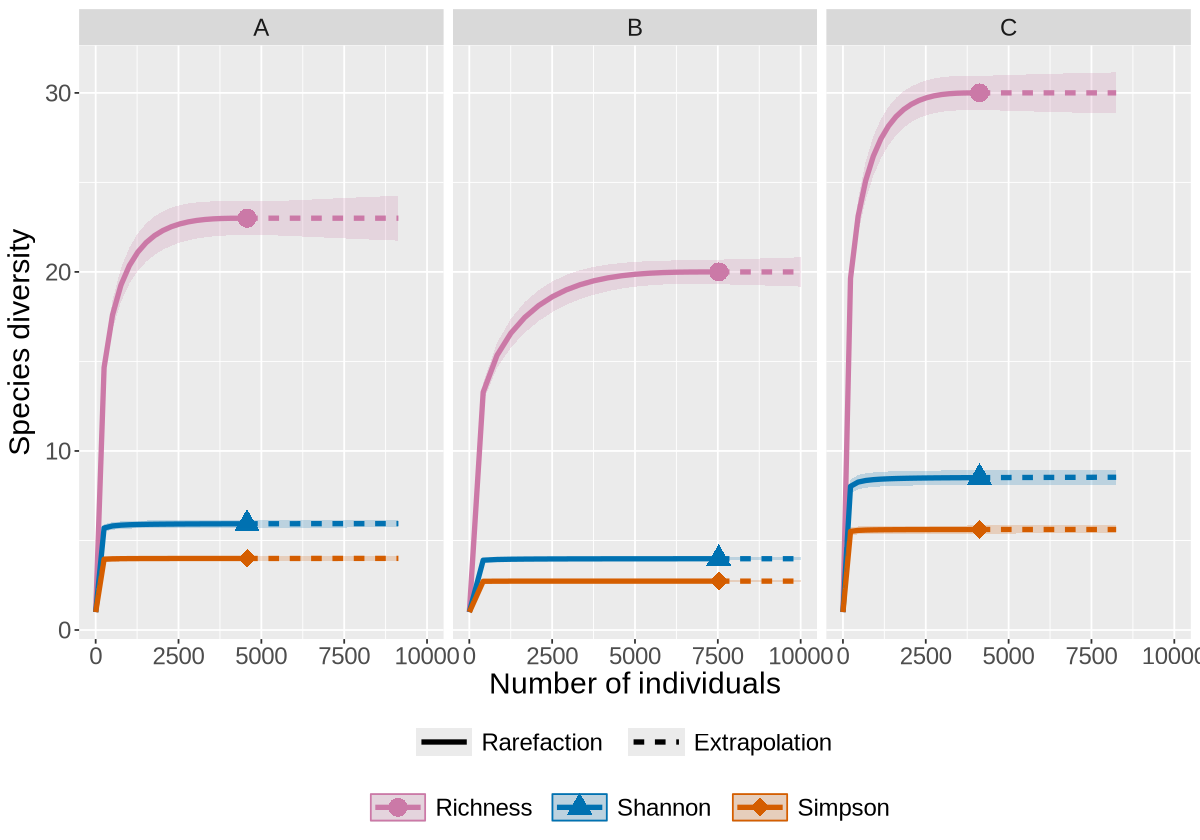

In [8]:
options(repr.plot.width = 10)
suppressMessages( {
    ggiNEXT(inext, type=1, facet.var="Assemblage") +
        # Change the color scale text and pick 3 colors
        scale_color_manual(
            name = "Diversity Order",
            labels = c("Richness", "Shannon", "Simpson"),
            values = c("#CC79A7", "#0072B2", "#D55E00") # Standard ggplot2 default colors
        ) +
        # Change the shape scale text to match the color scale exactly
        scale_shape_manual(
            name = "Diversity Order",
            labels = c("Richness", "Shannon", "Simpson"),
            values = c(16, 17, 18) # Filled circle, triangle, and diamond shapes
        ) +
        # Change the shaded area (fill) text to match
        scale_fill_manual(
            name = "Diversity Order",
            labels = c("Richness", "Shannon", "Simpson"),
            values = c("#CC79A7", "#0072B2", "#D55E00")
        ) + 
        scale_x_continuous(limits = c(0, 10000), oob=squish)
    }
)

### Sample-size-based diversity plots group by diversity metric

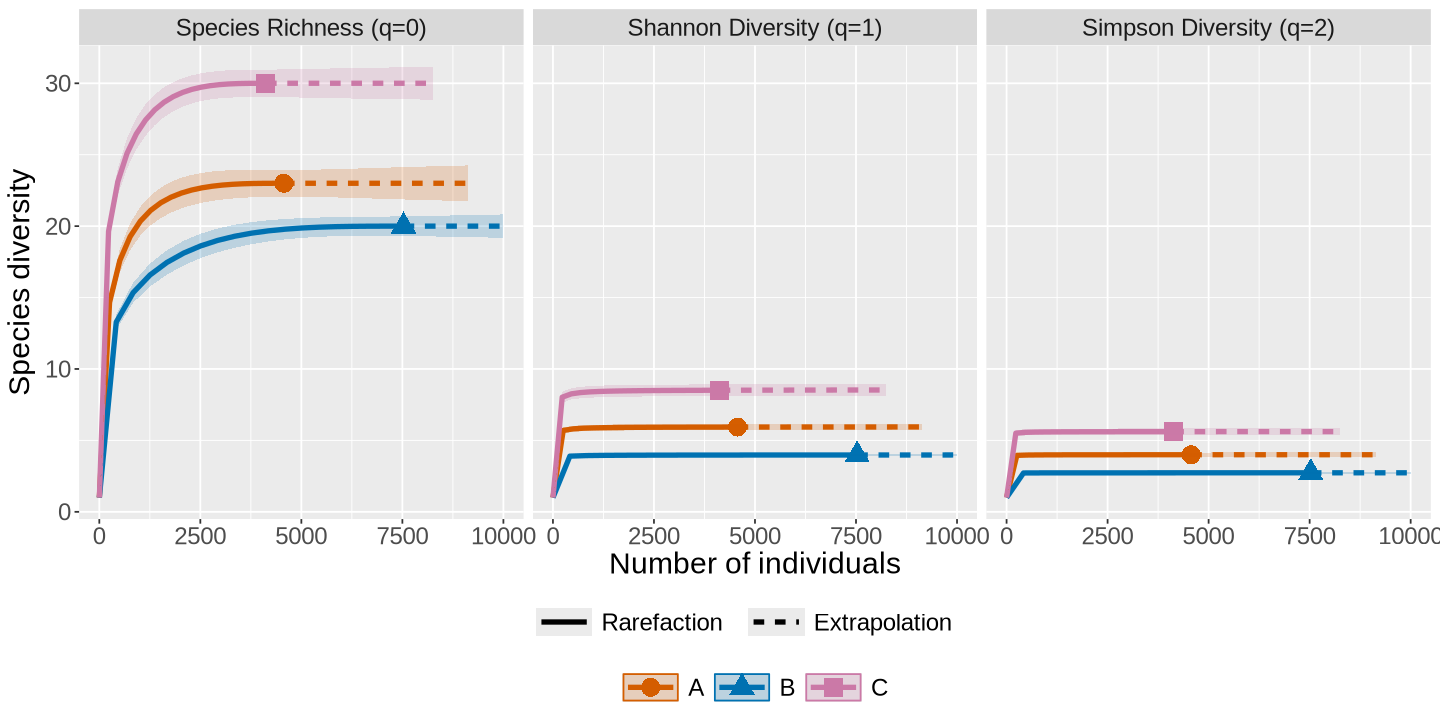

In [9]:
options(repr.plot.width = 12, repr.plot.height = 6)
ggiNEXT(inext, type=1, facet.var="Order.q", color.var="Assemblage") + 
    scale_x_continuous(limits = c(0, 10000), oob=squish) +
    facet_wrap(~ Order.q, labeller = as_labeller(
        c(
          "0" = "Species Richness (q=0)",
          "1" = "Shannon Diversity (q=1)",
          "2" = "Simpson Diversity (q=2)"
        )
    ))

### Sample coverage plot group by diversity

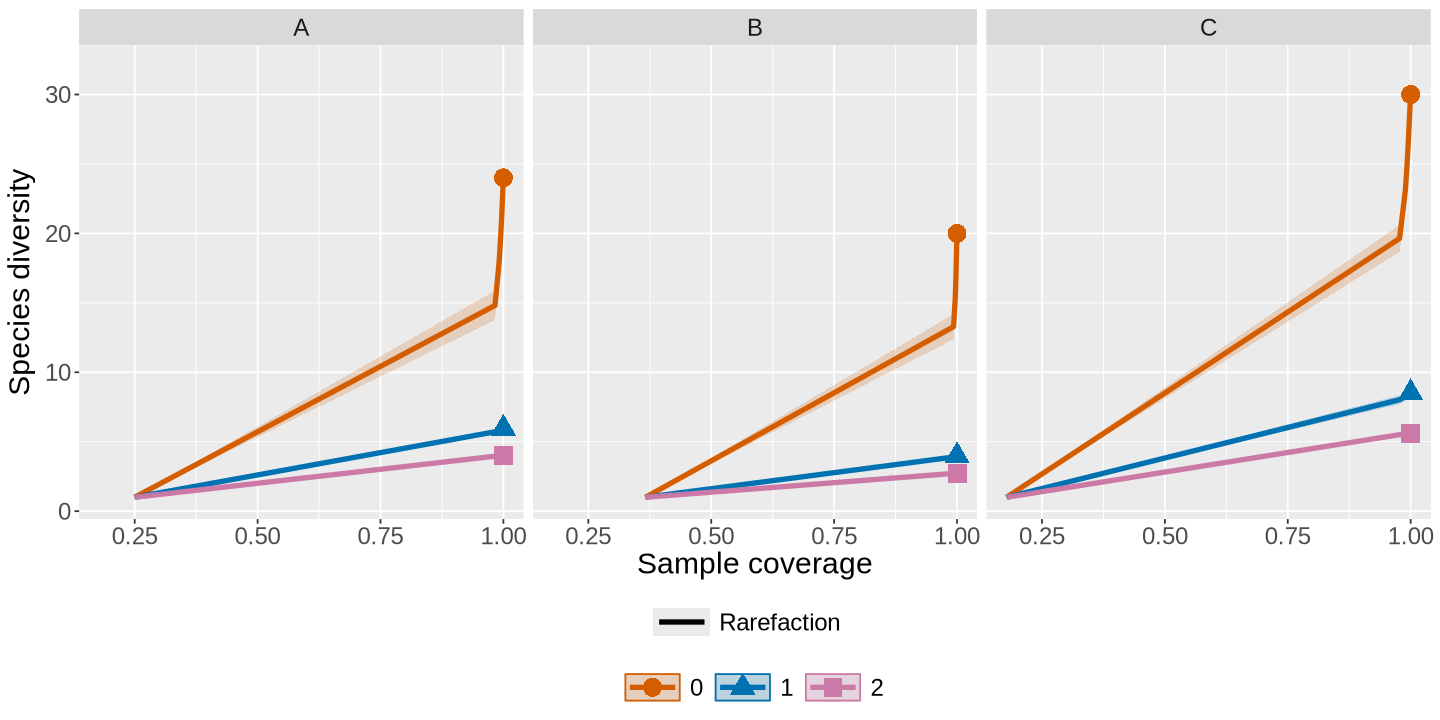

In [9]:
ggiNEXT(inext, type=3, facet.var="Assemblage")

### Sample coverage plot group by diversity metric

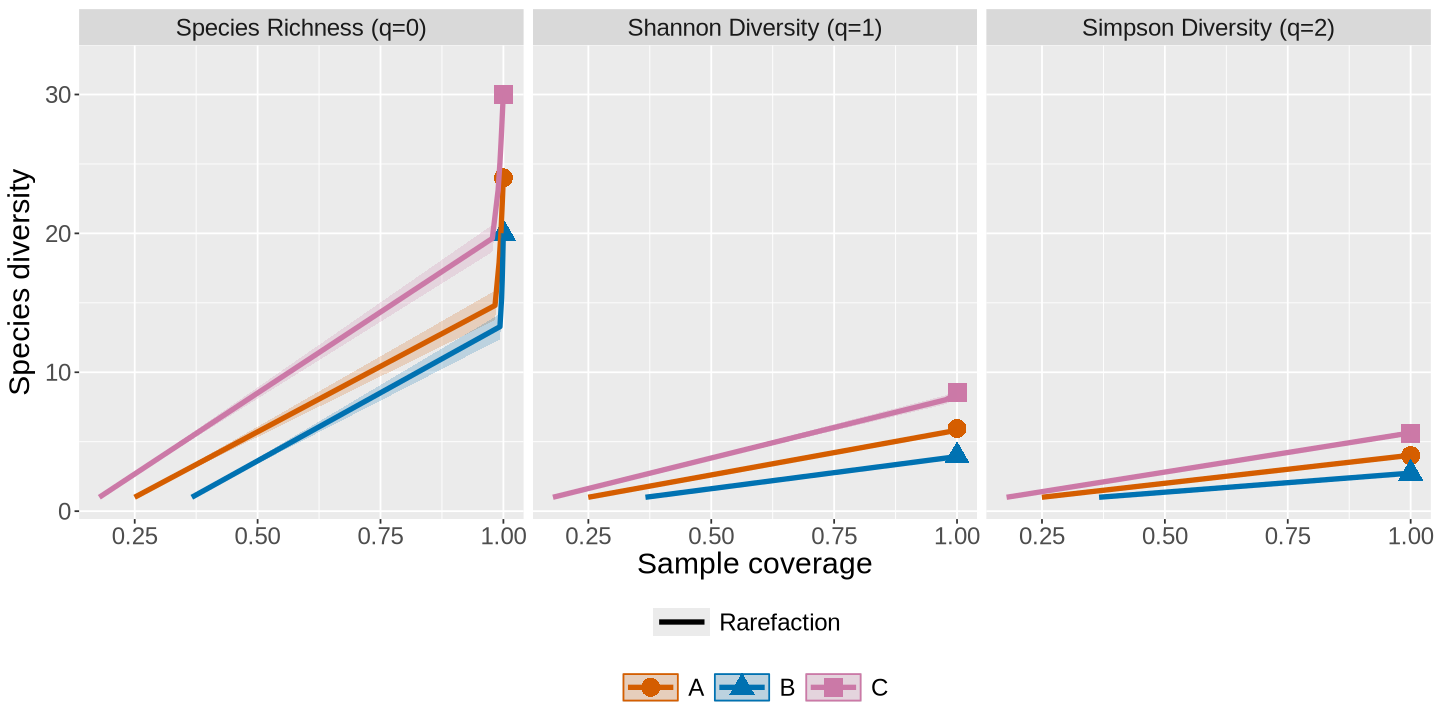

In [10]:
ggiNEXT(inext, type=3, facet.var="Order.q", color.var="Assemblage") +
    facet_wrap(~ Order.q, labeller = as_labeller(
        c(
          "0" = "Species Richness (q=0)",
          "1" = "Shannon Diversity (q=1)",
          "2" = "Simpson Diversity (q=2)"
        )
    ))

## 2. Diversity by Transect and Wood Texture

In [11]:
saproxylic_df <- cbind(environment_df$Transect, environment_df$Wood.Texture, saproxylic_community_df)
names(saproxylic_df)[1:2] =  c("Transect", "Wood.Texture")         # Environment columns as Site
saproxylic_df <- saproxylic_df %>%
    group_by(Transect, Wood.Texture) %>%
    summarise(
        across(3:last_col(), sum),                                 # OTU counts
        .groups = "drop"
      ) %>%
    mutate(Site = paste(Transect,".",Wood.Texture, sep="")) %>%    # New site column
    relocate(Site) %>%
    select(-Transect, -Wood.Texture)                               # Remove environment columns

site_names = saproxylic_df$Site

saproxylic_df <- saproxylic_df %>%
    select(-Site)
saproxylic_df <- as.data.frame(t(saproxylic_df))
names(saproxylic_df) <- site_names
head(saproxylic_df)

,A.Hardwood,A.Softwood,B.Hardwood,B.Softwood,C.Hardwood,C.Softwood
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Ascocoryne,0,0,1,69,1,36
Atheliachaete,0,0,0,3,0,0
Botryobasidium,0,0,0,6,0,0
Ceraceomyces,42,39,1,3,928,20
Cistella,4,10,0,0,0,40
Claussenomyces,0,0,0,0,0,5


In [12]:
# Prepare the abundance list for iNEXT
abundance_list <- lapply(saproxylic_df, function(x) x[x != 0])
abundance_list

$A.Hardwood
 [1]  42   4  13   3 167   2   2   5  31  24  77  40  51 296   6  10  19 676

$A.Softwood
 [1]   39   10   20    1    3  433   10    1  540    1    1    5  109    7   41
[16]   36  558    3    2    1    4 1268

$B.Hardwood
 [1]    1    1    5   71   86  118    1    6  102  771   11   16    2 2029

$B.Softwood
 [1]   69    3    6    3    5   49    5   51  135   25   32   18    7   55 1480
[16]   45  426    3    1 1890

$C.Hardwood
 [1]   1 928  91   2 196  49 279   2   2   3   1  54  28   2   2  27   2   1   3
[20]   4   8   1

$C.Softwood
 [1]   36   20   40    5    2   46   11    8  654    1    5   50   21    9   27
[16]    5   17   19    3  126 1059    4    9    3   59    3

In [13]:
# computes rarefaction (interpolation) and extrapolation (prediction) sampling curves for biodiversity 
# standard comparisons across communities using Hill numbers 
# (q=0 for species richness, q=1 for Shannon diversity, and q=2 for Simpson diversity) based on sample size or sample coverage.
inext <- iNEXT(abundance_list, q=c(0, 1, 2), datatype="abundance")

### Sample-size-based diversity plots group by transect

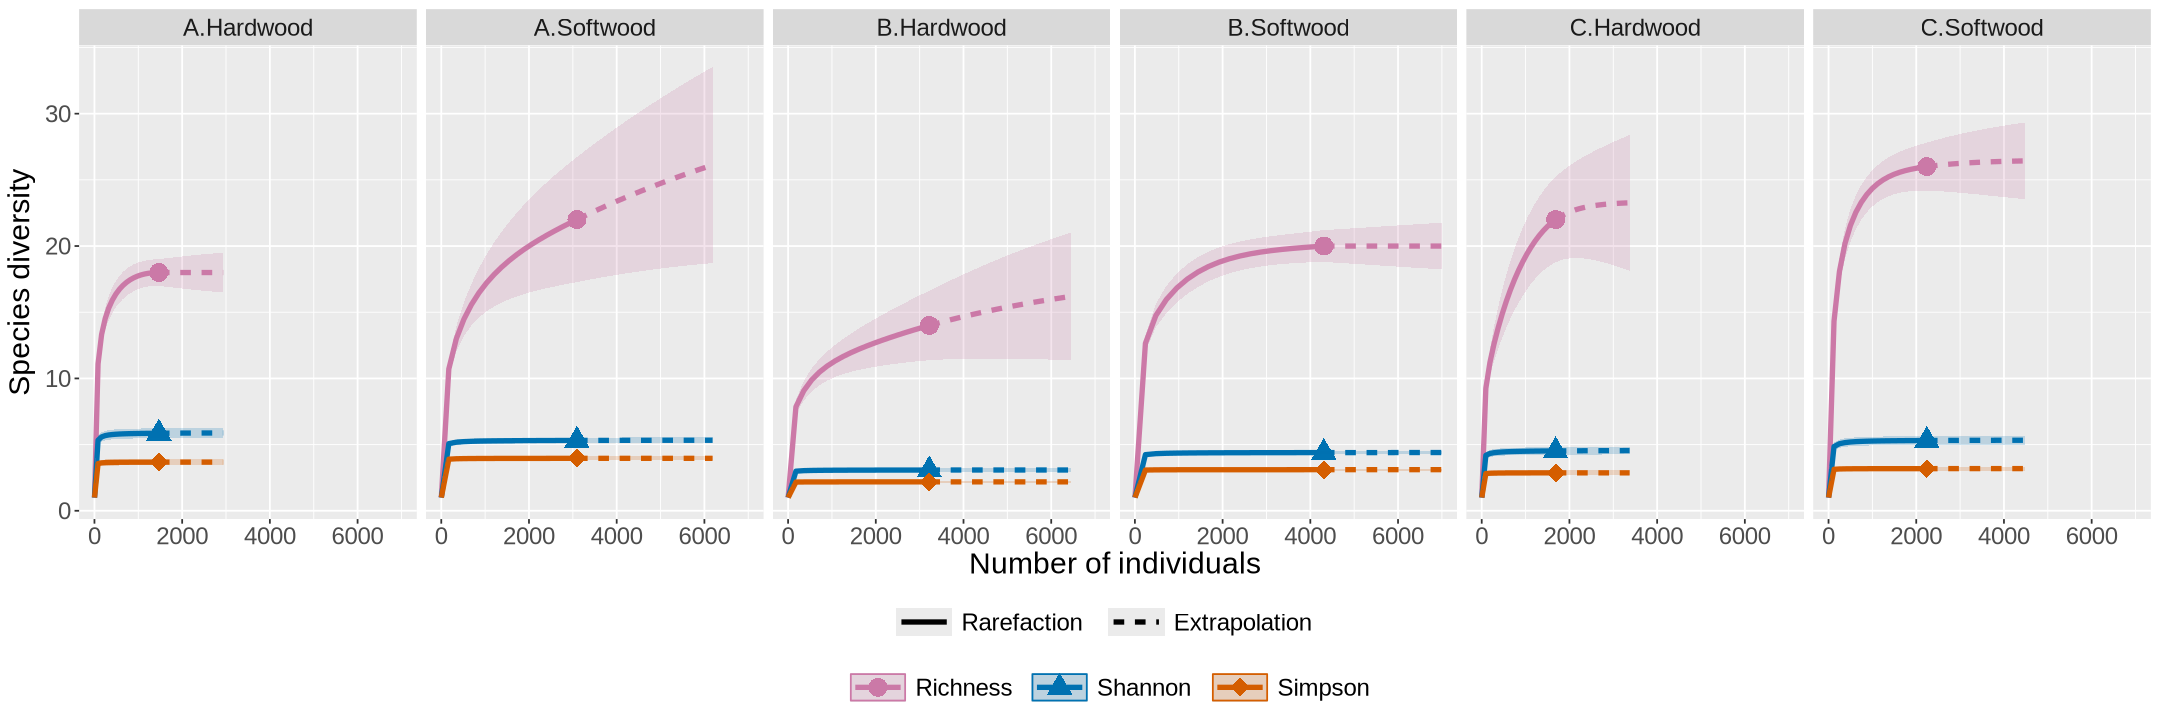

In [14]:
options(repr.plot.width = 18, repr.plot.height = 6)
suppressMessages( {
    ggiNEXT(inext, type=1, facet.var="Assemblage") +
        # Change the color scale text and pick 3 colors
        scale_color_manual(
            name = "Diversity Order",
            labels = c("Richness", "Shannon", "Simpson"),
            values = c("#CC79A7", "#0072B2", "#D55E00") # Standard ggplot2 default colors
        ) +
        # Change the shape scale text to match the color scale exactly
        scale_shape_manual(
            name = "Diversity Order",
            labels = c("Richness", "Shannon", "Simpson"),
            values = c(16, 17, 18) # Filled circle, triangle, and diamond shapes
        ) +
        # Change the shaded area (fill) text to match
        scale_fill_manual(
            name = "Diversity Order",
            labels = c("Richness", "Shannon", "Simpson"),
            values = c("#CC79A7", "#0072B2", "#D55E00")
        ) + 
        scale_x_continuous(limits = c(0, 7000), oob=squish)
    }
)

### Sample-size-based diversity plots group by diversity metric

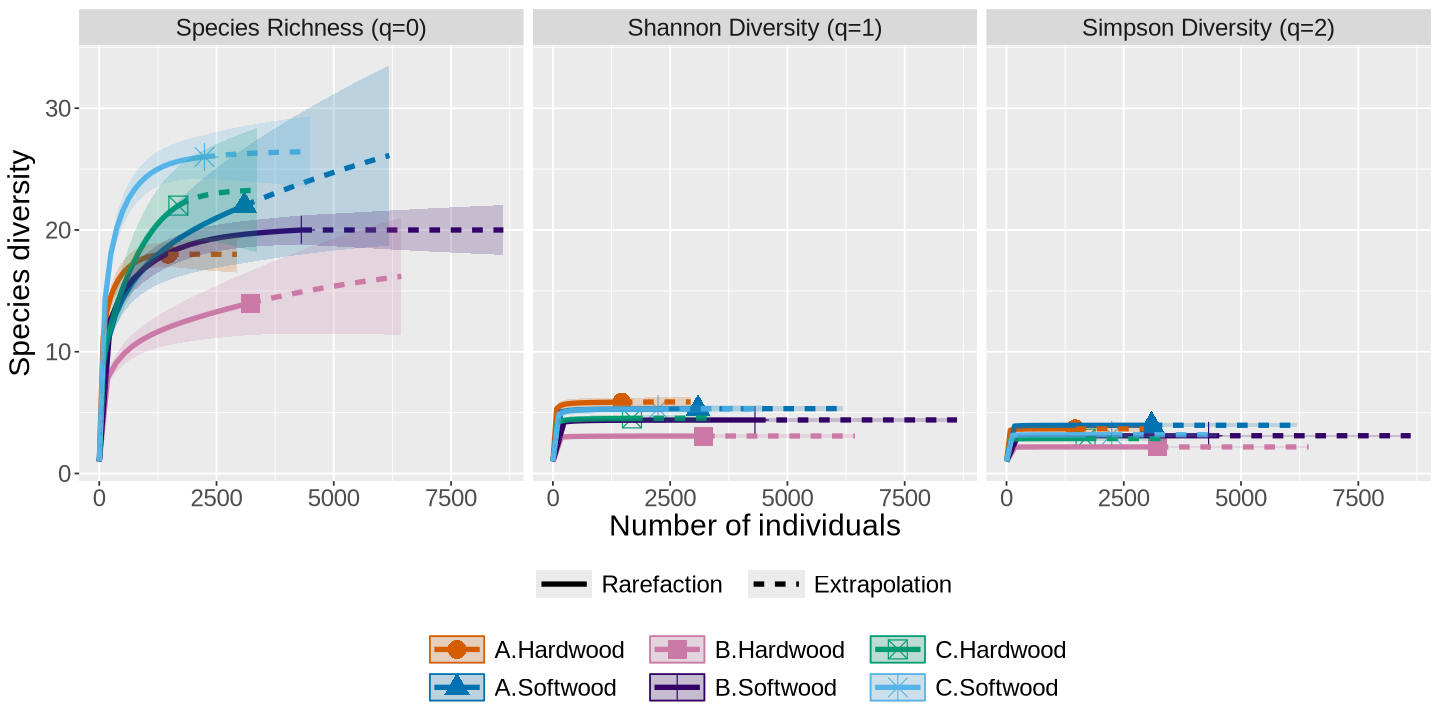

In [15]:
options(repr.plot.width = 12, repr.plot.height = 6)
ggiNEXT(inext, type=1, facet.var="Order.q", color.var="Assemblage") +
    facet_wrap(~ Order.q, labeller = as_labeller(
        c(
          "0" = "Species Richness (q=0)",
          "1" = "Shannon Diversity (q=1)",
          "2" = "Simpson Diversity (q=2)"
        )
    ))

### Sample coverage plot group by diversity

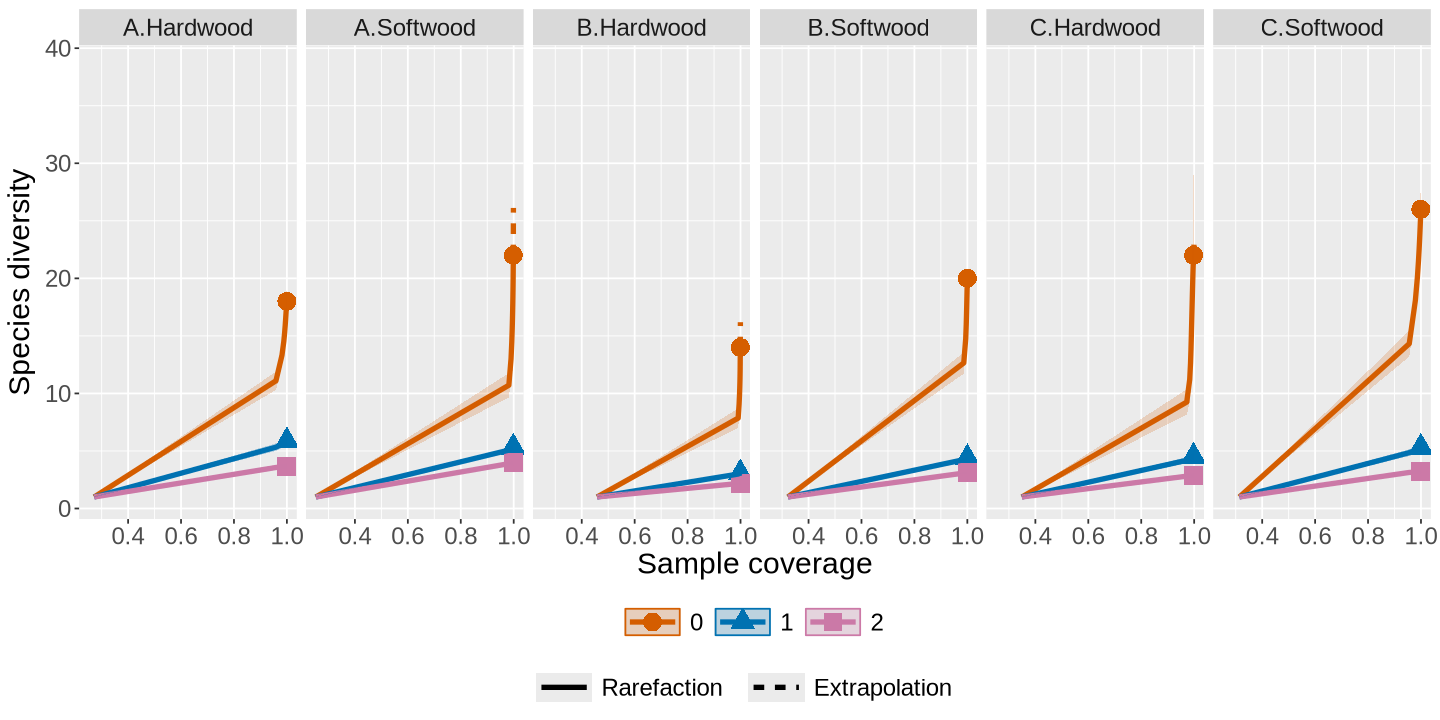

In [16]:
options(repr.plot.width = 12, repr.plot.height = 6)
ggiNEXT(inext, type=3, facet.var="Assemblage")

### Sample coverage plot group by diversity metric

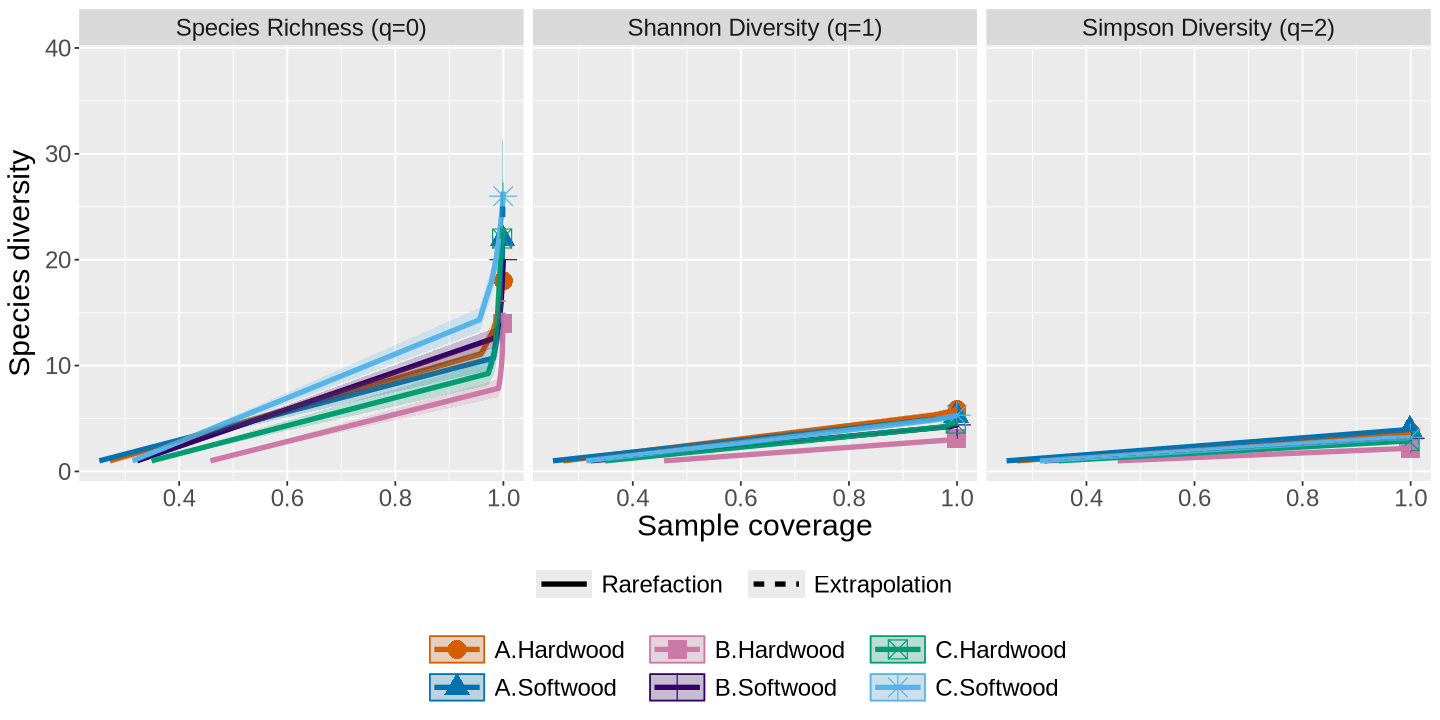

In [17]:
ggiNEXT(inext, type=3, facet.var="Order.q", color.var="Assemblage") +
    facet_wrap(~ Order.q, labeller = as_labeller(
        c(
          "0" = "Species Richness (q=0)",
          "1" = "Shannon Diversity (q=1)",
          "2" = "Simpson Diversity (q=2)"
        )
    ))

## 2.3. Diversity by Transect and Wood Type

In [18]:
saproxylic_df <- cbind(environment_df$Transect, environment_df$Wood.Type, saproxylic_community_df)
names(saproxylic_df)[1:2] =  c("Transect", "Wood.Type")         # Environment columns as Site
saproxylic_df <- saproxylic_df %>%
    group_by(Transect, Wood.Type) %>%
    summarise(
        across(3:last_col(), sum),                              # OTU counts
        .groups = "drop"
      ) %>%
    mutate(Site = paste(Transect,".",Wood.Type, sep="")) %>%    # New site column
    relocate(Site) %>%
    select(-Transect, -Wood.Type)                               # Remove environment columns

site_names = saproxylic_df$Site

saproxylic_df <- saproxylic_df %>%
    select(-Site)
saproxylic_df <- as.data.frame(t(saproxylic_df))
names(saproxylic_df) <- site_names
head(saproxylic_df)

,A.Birch,A.Pine,A.Spruce,B.Birch,B.Pine,B.Spruce,C.Birch,C.Pine,C.Spruce
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Ascocoryne,0,0,0,1,67,2,1,35,1
Atheliachaete,0,0,0,0,3,0,0,0,0
Botryobasidium,0,0,0,0,6,0,0,0,0
Ceraceomyces,42,3,36,1,0,3,928,19,1
Cistella,4,5,5,0,0,0,0,9,31
Claussenomyces,0,0,0,0,0,0,0,0,5


In [19]:
# Prepare the abundance list for iNEXT
abundance_list <- lapply(saproxylic_df, function(x) x[x != 0])
abundance_list

$A.Birch
 [1]  42   4  13   3 167   2   2   5  31  24  77  40  51 296   6  10  19 676

$A.Pine
 [1]   3   5  17 212   1 528   4  15   1  28   2  41   3   2   1   4 894

$A.Spruce
 [1]  36   5   3   1   3 221  10  12   1   1   1  94   6  13  34 517 374

$B.Birch
 [1]    1    1    5   71   86  118    1    6  102  771   11   16    2 2029

$B.Pine
 [1]   67    3    6    3   41  108   24   29   16    2   31  379    7  422    1
[16] 1123

$B.Spruce
 [1]    2    3    2   49    5   10   27    1    3    2    5   24 1101   38    4
[16]    3  767

$C.Birch
 [1]   1 928  91   2 196  49 279   2   2   3   1  54  28   2   2  27   2   1   3
[20]   4   8   1

$C.Pine
 [1]   35   19    9    2    8    8  536    1    4    4   10    7   14    5    9
[16]   17   73 1056    2    3   59    3

$C.Spruce
 [1]   1   1  31   5  46   3 118   1  46  11   2  13   8   2   3  53   3   2   9

In [20]:
# computes rarefaction (interpolation) and extrapolation (prediction) sampling curves for biodiversity 
# standard comparisons across communities using Hill numbers 
# (q=0 for species richness, q=1 for Shannon diversity, and q=2 for Simpson diversity) based on sample size or sample coverage.
inext <- iNEXT(abundance_list, q=c(0, 1, 2), datatype="abundance")

### Sample-size-based diversity plots group by transect

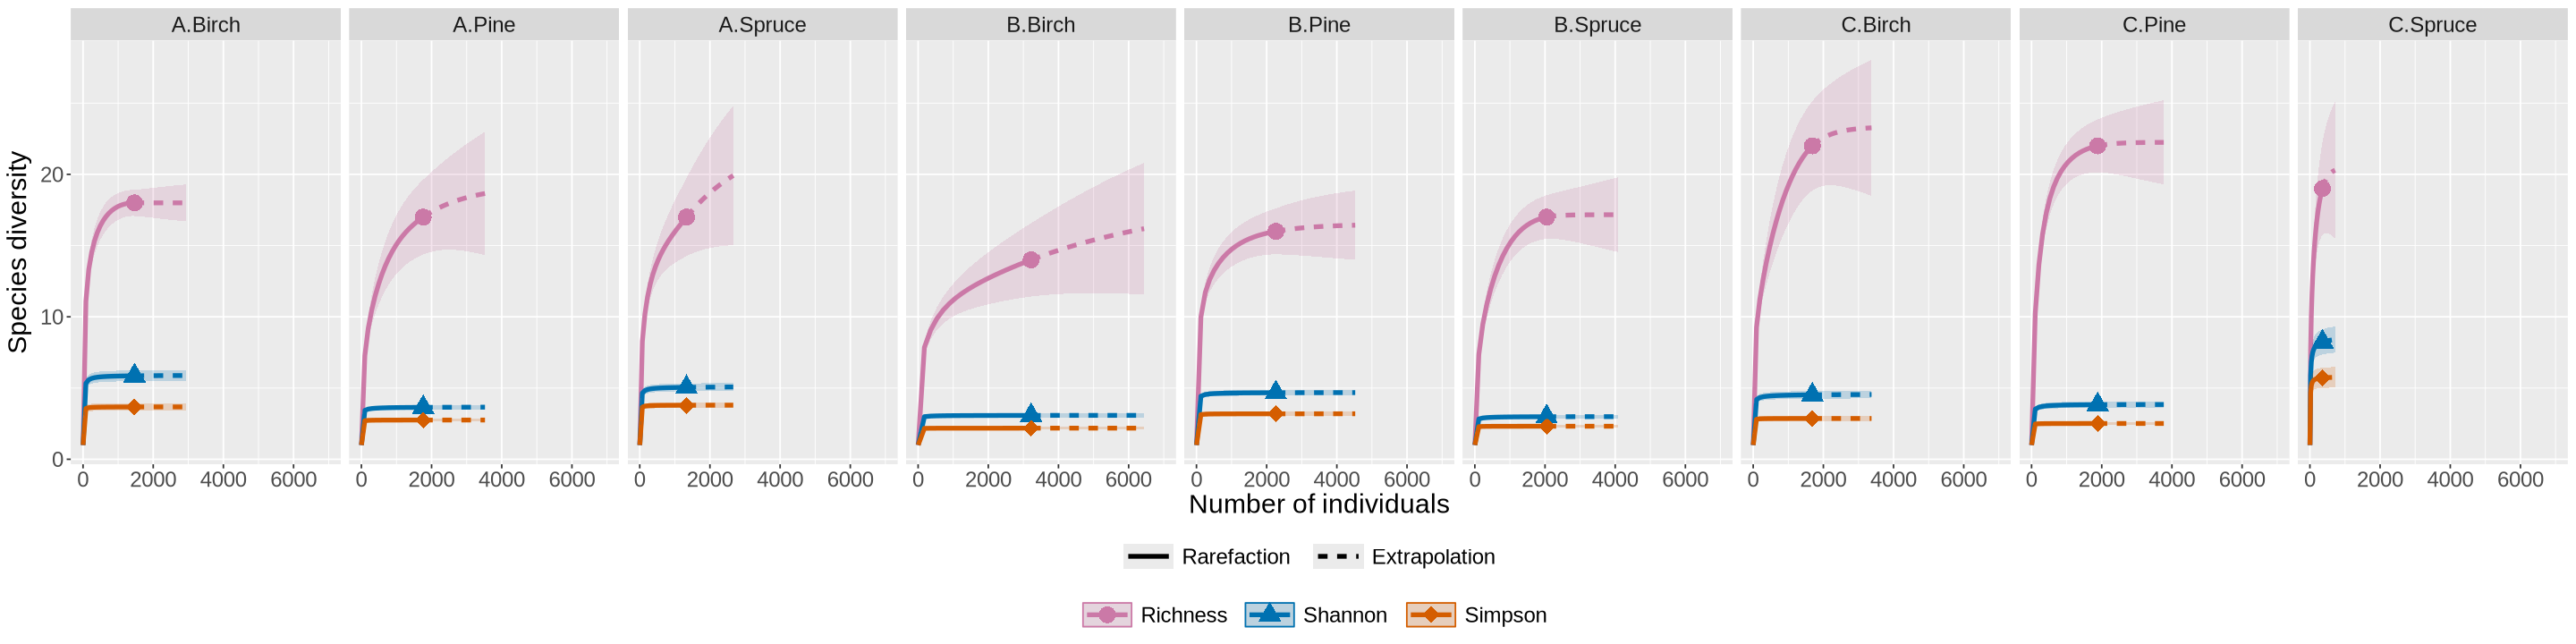

In [21]:
options(repr.plot.width = 24, repr.plot.height = 6)
suppressMessages( {
    ggiNEXT(inext, type=1, facet.var="Assemblage") +
        # Change the color scale text and pick 3 colors
        scale_color_manual(
            name = "Diversity Order",
            labels = c("Richness", "Shannon", "Simpson"),
            values = c("#CC79A7", "#0072B2", "#D55E00") # Standard ggplot2 default colors
        ) +
        # Change the shape scale text to match the color scale exactly
        scale_shape_manual(
            name = "Diversity Order",
            labels = c("Richness", "Shannon", "Simpson"),
            values = c(16, 17, 18) # Filled circle, triangle, and diamond shapes
        ) +
        # Change the shaded area (fill) text to match
        scale_fill_manual(
            name = "Diversity Order",
            labels = c("Richness", "Shannon", "Simpson"),
            values = c("#CC79A7", "#0072B2", "#D55E00")
        ) + 
        scale_x_continuous(limits = c(0, 7000), oob=squish)
    }
)

### Sample-size-based diversity plots group by diversity metric

Warning message:
“The shape palette can deal with a maximum of 6 discrete values because more
than 6 becomes difficult to discriminate
ℹ you have requested 9 values. Consider specifying shapes manually if you need
  that many of them.”
Warning message:
“Removed 9 rows containing missing values or values outside the scale range
(`geom_point()`).”


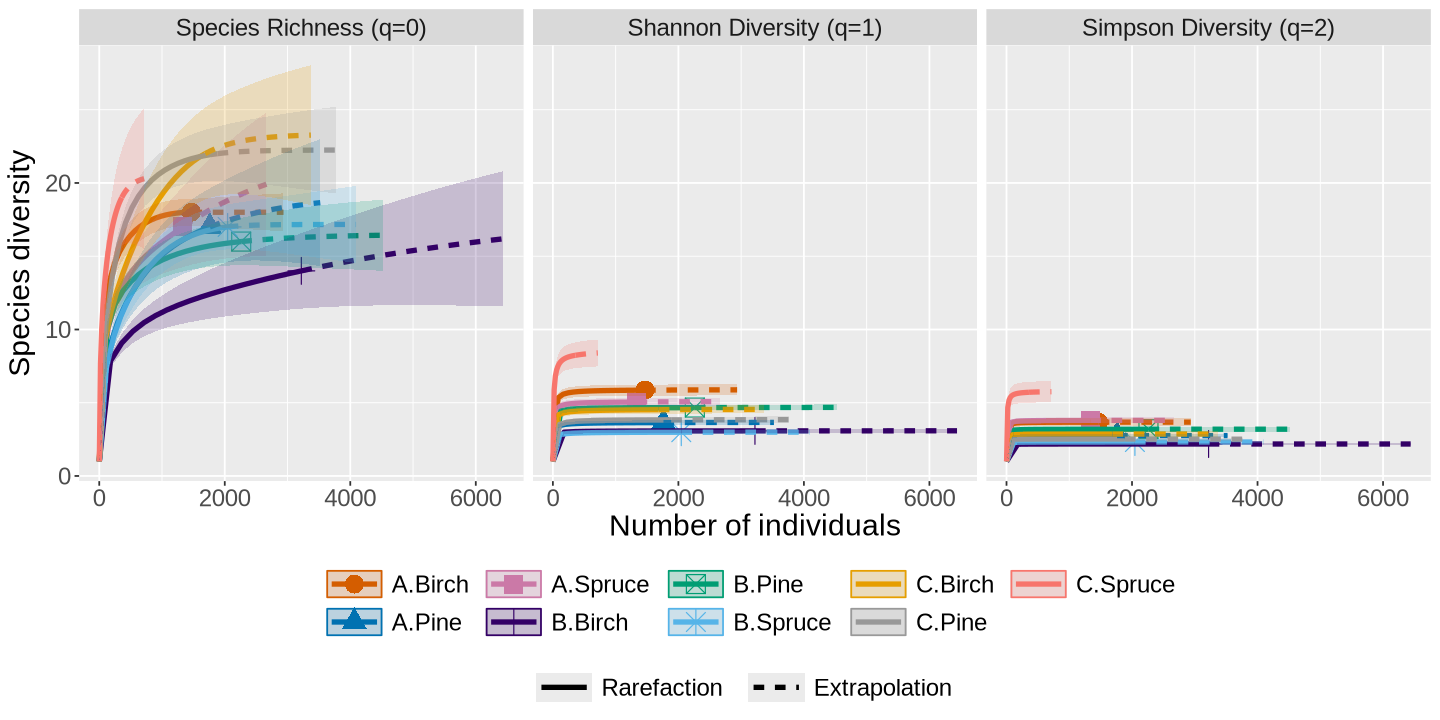

In [22]:
options(repr.plot.width = 12, repr.plot.height = 6)
ggiNEXT(inext, type=1, facet.var="Order.q", color.var="Assemblage") +
    facet_wrap(~ Order.q, labeller = as_labeller(
        c(
          "0" = "Species Richness (q=0)",
          "1" = "Shannon Diversity (q=1)",
          "2" = "Simpson Diversity (q=2)"
        )
    ))

### Sample coverage plot group by diversity

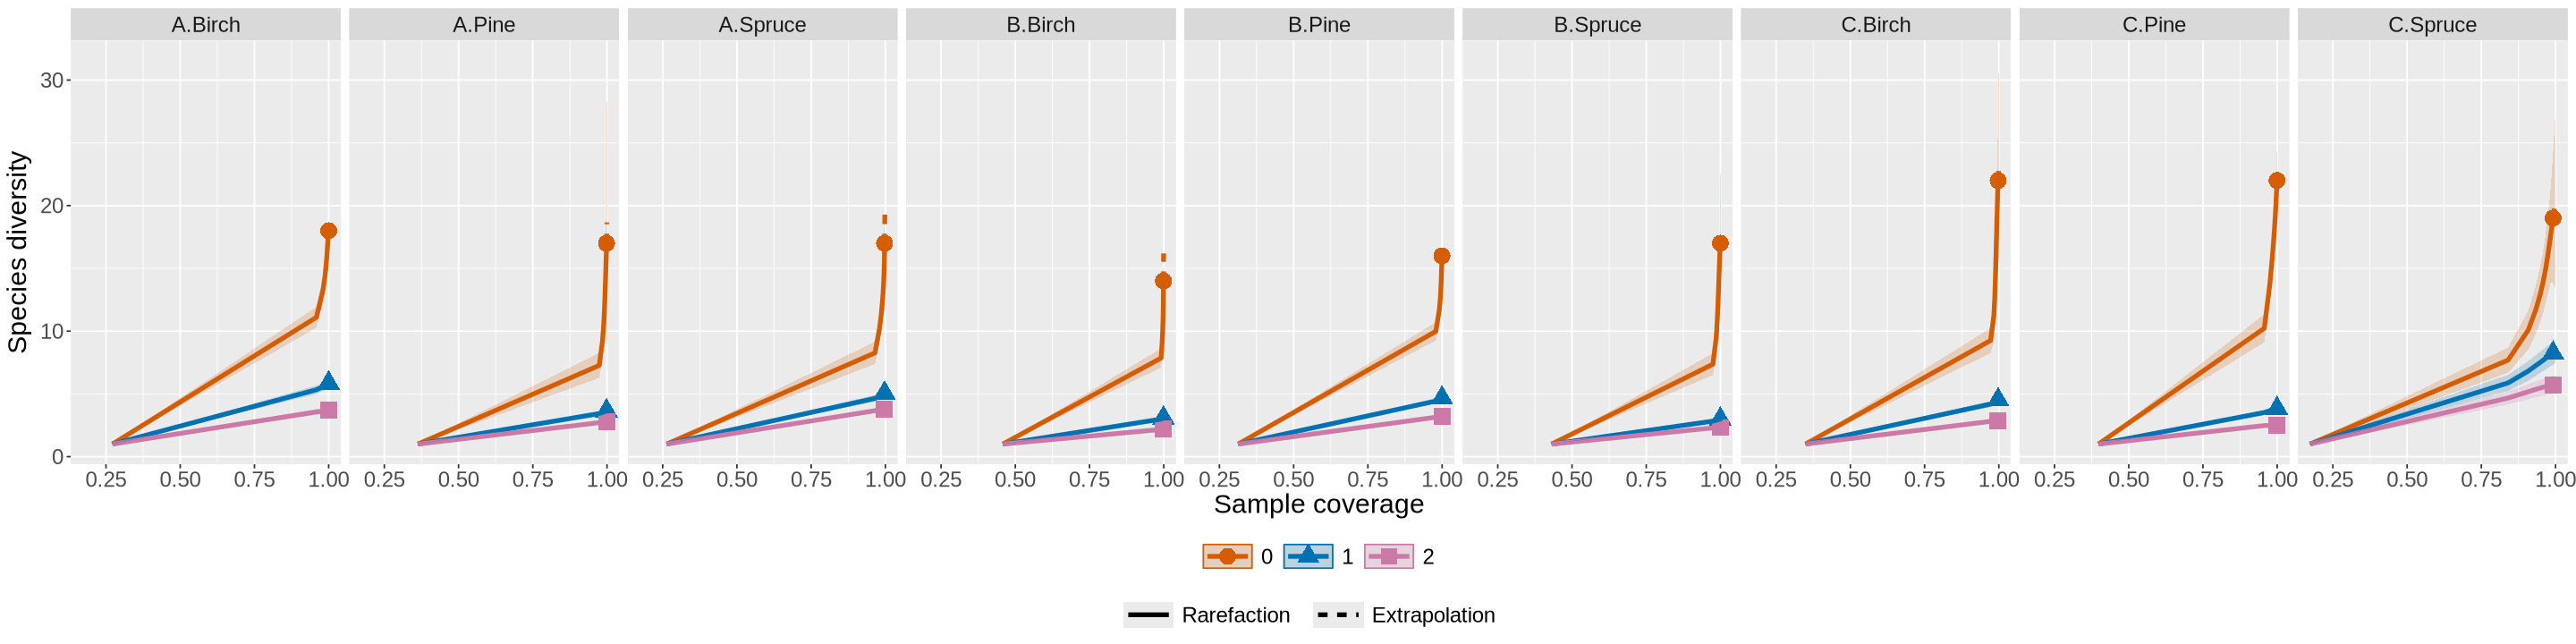

In [23]:
options(repr.plot.width = 24, repr.plot.height = 6)
ggiNEXT(inext, type=3, facet.var="Assemblage")

### Sample coverage plot group by diversity metric

Warning message:
“The shape palette can deal with a maximum of 6 discrete values because more
than 6 becomes difficult to discriminate
ℹ you have requested 9 values. Consider specifying shapes manually if you need
  that many of them.”
Warning message:
“Removed 9 rows containing missing values or values outside the scale range
(`geom_point()`).”


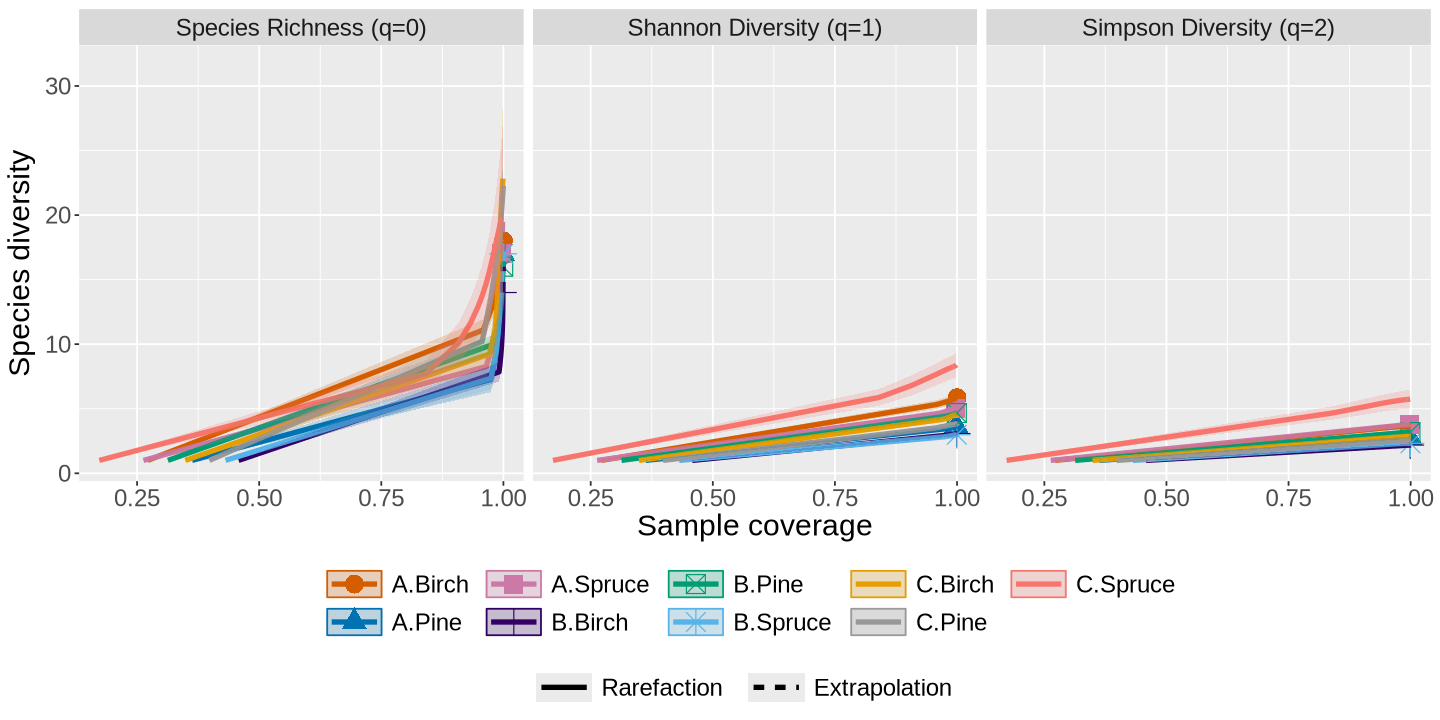

In [25]:
options(repr.plot.width = 12, repr.plot.height = 6)
ggiNEXT(inext, type=3, facet.var="Order.q", color.var="Assemblage") +
    facet_wrap(~ Order.q, labeller = as_labeller(
        c(
          "0" = "Species Richness (q=0)",
          "1" = "Shannon Diversity (q=1)",
          "2" = "Simpson Diversity (q=2)"
        )
    ))

## 2.4. Interpretation

TODO